In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

In [4]:
DATA_PATH=r"/hour.csv"
FIG_DIR="graphs"
os.makedirs(FIG_DIR,exist_ok=True)

In [5]:
#1. data upload and exploration

In [6]:
df=pd.read_csv(DATA_PATH)
print(df.shape)
print(df.head())
print(df["cnt"].describe())

(17379, 17)
   instant      dteday  season  yr  mnth  hr  holiday  weekday  workingday  \
0        1  2011-01-01       1   0     1   0        0        6           0   
1        2  2011-01-01       1   0     1   1        0        6           0   
2        3  2011-01-01       1   0     1   2        0        6           0   
3        4  2011-01-01       1   0     1   3        0        6           0   
4        5  2011-01-01       1   0     1   4        0        6           0   

   weathersit  temp   atemp   hum  windspeed  casual  registered  cnt  
0           1  0.24  0.2879  0.81        0.0       3          13   16  
1           1  0.22  0.2727  0.80        0.0       8          32   40  
2           1  0.22  0.2727  0.80        0.0       5          27   32  
3           1  0.24  0.2879  0.75        0.0       3          10   13  
4           1  0.24  0.2879  0.75        0.0       0           1    1  
count    17379.000000
mean       189.463088
std        181.387599
min          1.000000

In [7]:
#2. feature/target and train-val-test split

In [8]:
X=df.drop(columns=["instant", "dteday","casual","registered","cnt"])
y=df["cnt"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.15, random_state=42)

In [9]:
#3. model and training

In [10]:
#tree based model: no need for scaling or one-hot encoding
model = XGBRegressor(
    n_estimators=3000,   #upper limit, early stopping
    learning_rate=0.05,
    max_depth=7,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,   #min Hessian sums in a leaf
    reg_lambda=1.0,
    tree_method="hist",
    early_stopping_rounds=100,
    eval_metric="rmse",
    random_state=42,
)
model.fit(X_tr, y_tr, eval_set=[(X_tr, y_tr), (X_val, y_val)], verbose=500)
print(f"best iteration: {model.best_iteration}")

[0]	validation_0-rmse:175.43823	validation_1-rmse:173.32709
[500]	validation_0-rmse:20.49037	validation_1-rmse:38.95041
[673]	validation_0-rmse:17.51906	validation_1-rmse:39.09130
best iteration: 573


In [11]:
#4. evaluation

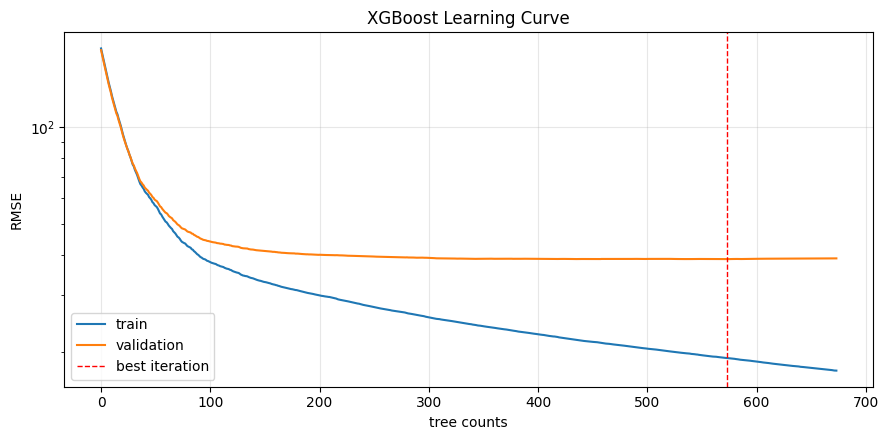

In [13]:
booster=model.get_booster()
past=model.evals_result()
train_rmse,val_rmse=past["validation_0"]["rmse"],past["validation_1"]["rmse"]
fig, ax=plt.subplots(figsize=(9,4.5))
ax.plot(train_rmse,label="train")
ax.plot(val_rmse,label="validation")
ax.axvline(model.best_iteration, color="r", ls="--", lw=1,
           label="best iteration")
ax.set(title="XGBoost Learning Curve", xlabel="tree counts", ylabel="RMSE", yscale="log")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/xgb_learning_curve.png", dpi=150)
plt.show()

    ID     Feature  Split   Yes    No        Gain   Cover
0  0-0          hr    7.0   0-1   0-2  94203790.0  9434.0
1  0-1          hr    6.0   0-3   0-4    813776.0  2680.0
2  0-2        temp    0.5   0-5   0-6  32757376.0  6754.0
3  0-3          hr    2.0   0-7   0-8    323720.0  2292.0
4  0-4  workingday    1.0   0-9  0-10    553187.5   388.0
5  0-5          yr    1.0  0-11  0-12   8568192.0  3059.0
6  0-6          yr    1.0  0-13  0-14  16352272.0  3695.0
hr            0.286
workingday    0.227
yr            0.184
season        0.076
atemp         0.050
temp          0.050
weathersit    0.044
weekday       0.029
mnth          0.017
hum           0.016
holiday       0.015
windspeed     0.006
dtype: float64


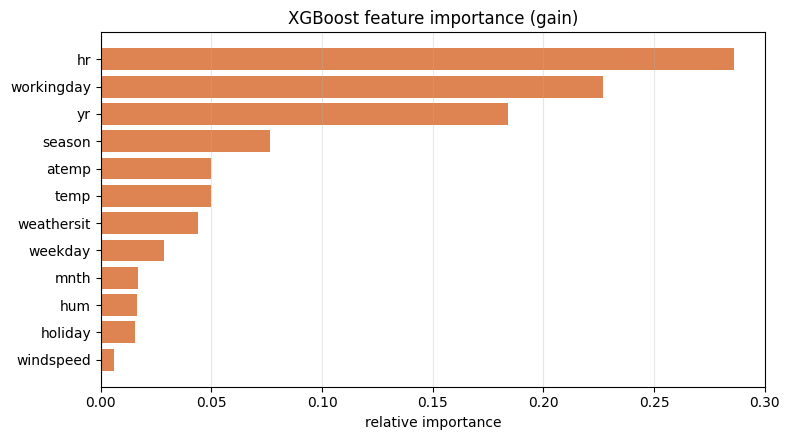

In [14]:
trees=booster.trees_to_dataframe()
print(trees[trees["Tree"]==0][["ID", "Feature", "Split", "Yes", "No", "Gain", "Cover"]].head(7))
imp=pd.Series(booster.get_score(importance_type="gain"))
imp=(imp/imp.sum()).sort_values()
print(imp.sort_values(ascending=False).round(3))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(imp.index, imp.values, color="#DD8452")
ax.set(title="XGBoost feature importance (gain)", xlabel="relative importance")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/xgb_feature_importance.png", dpi=150)
plt.show()

In [15]:
#5. prediction

In [16]:
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

comprs = X_test[["hr", "workingday", "weathersit", "temp"]].assign(
    real=y_test, pred=y_pred_test.round(0), err=(y_test - y_pred_test).round(0)
)
print(comprs.head(10))

# newscenarios. Normalization: temp=°C/41, atemp=°C/50, hum=%/100, windspeed=km/s/67
mutual = dict(holiday=0, temp=20 / 41, atemp=20 / 50, hum=0.55, windspeed=10 / 67)
sces = pd.DataFrame({
    "workday 08:00, sunny": dict(season=2, yr=1, mnth=5, hr=8, weekday=3, workingday=1, weathersit=1, **mutual),
    "workday 17:00, sunny": dict(season=2, yr=1, mnth=5, hr=17, weekday=3, workingday=1, weathersit=1, **mutual),
    "sunday 08:00, sunny": dict(season=2, yr=1, mnth=5, hr=8, weekday=0, workingday=0, weathersit=1, **mutual),
    "workday 03:00, rainy": dict(season=1, yr=1, mnth=1, hr=3, holiday=0, weekday=2, workingday=1,
                                    weathersit=3, temp=8 / 41, atemp=6 / 50, hum=0.90, windspeed=25 / 67),
}).T[X.columns].astype(float)
print(pd.Series(model.predict(sces).astype(float), index=sces.index).round(1))

exmp = sces.iloc[[0]]
stps = [1, 5, 20, 50, 100, 300, model.best_iteration + 1]
print(pd.Series({k: float(model.predict(exmp, iteration_range=(0, k))[0]) for k in stps},
                name="predict").rename_axis("tree count").round(1))

       hr  workingday  weathersit  temp  real   pred   err
12830  19           0           1  0.80   425  402.0  23.0
8688   20           0           1  0.24    88  100.0 -12.0
7091    2           1           1  0.32     4    9.0  -5.0
12230  19           1           1  0.78   526  545.0 -19.0
431     0           1           1  0.26    13   18.0  -5.0
1086    0           1           1  0.44    32   39.0  -7.0
11605  18           1           1  0.72   706  761.0 -55.0
7983    7           0           1  0.26    26   28.0  -2.0
10391   2           1           1  0.50     2   -2.0   4.0
7046    5           1           1  0.42    21   29.0  -8.0
workday 08:00, sunny    653.2
workday 17:00, sunny    629.6
sunday 08:00, sunny     161.7
workday 03:00, rainy     -9.4
dtype: float64
tree count
1      196.3
5      239.9
20     325.2
50     498.5
100    589.3
300    637.0
574    653.2
Name: predict, dtype: float64


In [17]:
#evaluation

In [19]:
def metrics3(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred)}

result = pd.DataFrame({"train": metrics3(y_train, y_pred_train),
                      "test": metrics3(y_test, y_pred_test)}).T
print(result.round(4))
print(f"negative pred: {(y_pred_test < 0).sum()} / {len(y_pred_test)}")

           MAE     RMSE      R2
train  14.1967  23.2143  0.9838
test   23.0342  37.8262  0.9548
negative pred: 75 / 3476


In [21]:
#7. visualization

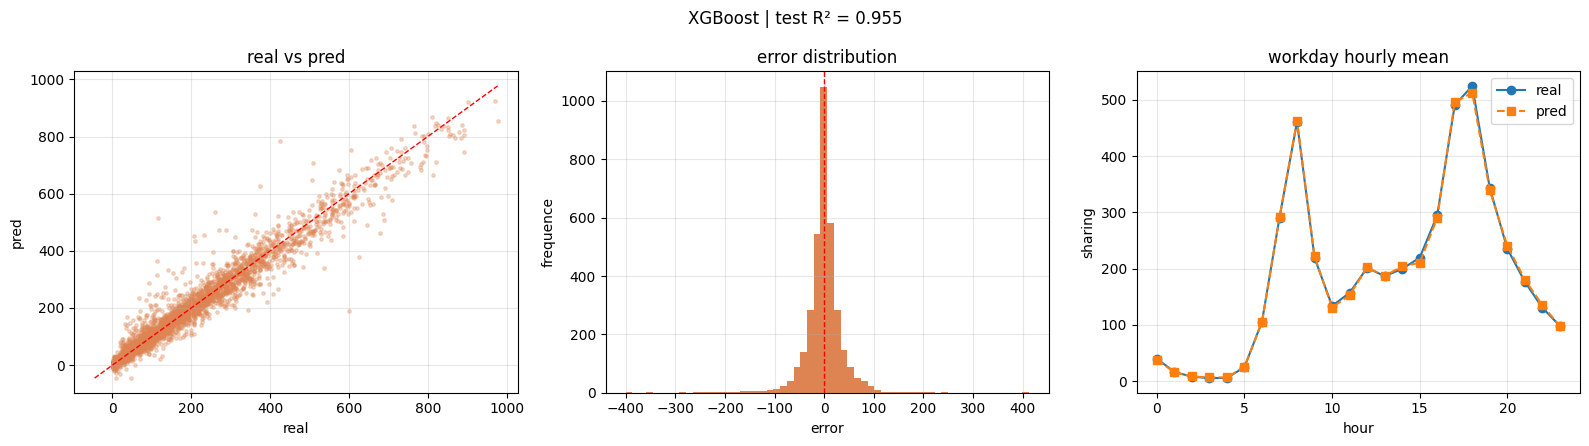

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].scatter(y_test, y_pred_test, s=6, alpha=0.3, color="#DD8452")
lim = [min(y_test.min(), y_pred_test.min()), y_test.max()]
axes[0].plot(lim, lim, "r--", lw=1)
axes[0].set(title="real vs pred", xlabel="real", ylabel="pred")

axes[1].hist(y_test - y_pred_test, bins=60, color="#DD8452")
axes[1].axvline(0, color="r", ls="--", lw=1)
axes[1].set(title="error distribution", xlabel="error", ylabel="frequence")

workday = (X_test.assign(real=y_test, pred=y_pred_test)
           .query("workingday == 1").groupby("hr")[["real", "pred"]].mean())
axes[2].plot(workday.index, workday["real"], "o-", label="real")
axes[2].plot(workday.index, workday["pred"], "s--", label="pred")
axes[2].set(title="workday hourly mean", xlabel="hour", ylabel="sharing")
axes[2].legend()

for a in axes:
    a.grid(alpha=0.3)
fig.suptitle(f"XGBoost | test R² = {result.loc['test', 'R2']:.3f}")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/xgb_results.png", dpi=150)
plt.show()